# TopK Sparse Autoencoder for UMedPT Interpretability

**Goal:** Train a TopK SAE on intermediate representations of UMedPT's Swin encoder to extract monosemantic, interpretable features from a medical vision transformer.

**Pipeline:**
1. **Phase 1 — Activation Harvesting:** Hook UMedPT's Swin encoder, pass medical images through, cache activations to disk.
2. **Phase 2 — TopK SAE Architecture:** A clean, minimal TopK sparse autoencoder.
3. **Phase 3 — Training Loop:** Train the SAE with MSE loss, track L0, variance explained, dead latents.
4. **Phase 4 — Interpretation:** Max-activating examples, spatial heatmaps, feature grids.

---

## 0. Imports & Configuration

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from dataclasses import dataclass
from typing import Optional, Tuple, List, Dict
from tqdm.notebook import tqdm
import json
import warnings
warnings.filterwarnings('ignore')

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA A100 80GB PCIe


In [16]:
@dataclass
class SAEConfig:
    """All hyperparameters for the TopK SAE pipeline."""
    
    # --- Activation Harvesting ---
    hook_layer: str = "layers.1"  # Swin stage to hook (see Phase 1 notes)
    num_harvest_images: int = 5000  # Number of images to pass through the model
    batch_size_harvest: int = 32  # Batch size for harvesting
    
    # --- SAE Architecture ---
    d_model: int = 384  # Will be set from actual activations (Swin channel dim)
    expansion_factor: int = 8  # Dictionary width = d_model * expansion_factor
    k: int = 32  # Number of active latents per sample in TopK
    
    # --- Training ---
    batch_size_train: int = 4096  # SAE training batch size (activation vectors)
    lr: float = 3e-4
    num_epochs: int = 15
    weight_decay: float = 0.0
    seed: int = 42
    
    # --- Auxiliary loss for dead latent revival ---
    aux_k: int = 512  # Number of dead latents to revive per step
    aux_coeff: float = 1/32  # Weight of auxiliary loss
    dead_threshold_steps: int = 10000  # Steps without activation to be considered dead
    
    # --- Interpretation ---
    top_k_examples: int = 10  # Number of max-activating examples per feature
    
    # --- Paths ---
    output_dir: str = "./sae_outputs"
    activation_cache_path: str = "./sae_outputs/activations"
    
    @property
    def d_sae(self) -> int:
        return self.d_model * self.expansion_factor

cfg = SAEConfig()
Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
Path(cfg.activation_cache_path).mkdir(parents=True, exist_ok=True)
print(f"SAE dictionary width: {cfg.d_model} x {cfg.expansion_factor} = {cfg.d_sae} latents")
print(f"TopK: {cfg.k} active latents per sample")

SAE dictionary width: 384 x 8 = 3072 latents
TopK: 32 active latents per sample


---
## Phase 1: Activation Harvesting

### Key decisions for Swin:
- **Swin is hierarchical** — it has stages with patch merging between them. Each stage halves spatial resolution and doubles channels.
- **Hook point:** We hook at the **output of a stage** (after the final Swin block in that stage, before patch merging). This gives us the richest representation at that resolution.
- **Spatial tokens as samples:** Each spatial position in the feature map is treated as an independent activation vector. For a 224×224 input with stage 2 output at 28×28 spatial, that's 784 activation vectors per image.
- **Normalization:** We normalize activations so their average squared L2 norm equals d_model (following Anthropic's practice).

In [17]:
class ActivationCache:
    """
    Hooks into a Swin encoder, collects activations from a specified layer,
    normalizes them, and saves to disk.
    
    The activations are flattened from (B, H, W, C) to (B*H*W, C) so each
    spatial position is treated as an independent sample for SAE training.
    """
    
    def __init__(self, model: nn.Module, hook_layer: str, device: torch.device):
        self.model = model
        self.hook_layer = hook_layer
        self.device = device
        self._activations = []
        self._hook_handle = None
        
    def _hook_fn(self, module, input, output):
        """Forward hook that captures the output tensor."""
        # Swin outputs can be (B, H, W, C) or (B, N, C) depending on the layer
        if isinstance(output, tuple):
            output = output[0]
        act = output.detach().cpu()
        # If 4D (B, H, W, C), reshape to (B*H*W, C)
        if act.ndim == 4:
            B, H, W, C = act.shape
            act = act.reshape(B * H * W, C)
        # If 3D (B, N, C), reshape to (B*N, C)
        elif act.ndim == 3:
            B, N, C = act.shape
            act = act.reshape(B * N, C)
        self._activations.append(act)
    
    def _find_layer(self, model: nn.Module, layer_name: str) -> nn.Module:
        """Navigate dotted layer name to find the module."""
        module = model
        for part in layer_name.split('.'):
            if part.isdigit():
                module = module[int(part)]
            else:
                module = getattr(module, part)
        return module
    
    def register_hook(self):
        """Attach the forward hook to the target layer."""
        target_layer = self._find_layer(self.model, self.hook_layer)
        self._hook_handle = target_layer.register_forward_hook(self._hook_fn)
        print(f"Hook registered on: {self.hook_layer}")
        print(f"Target module type: {type(target_layer).__name__}")
        return self
    
    def remove_hook(self):
        if self._hook_handle is not None:
            self._hook_handle.remove()
            self._hook_handle = None
    
    @torch.no_grad()
    def harvest(self, dataloader: DataLoader) -> torch.Tensor:
        """
        Run the model on all batches, collect activations, normalize.
        
        Returns:
            activations: (N_total, D) tensor of normalized activation vectors
        """
        self.model.eval()
        self._activations = []
        
        print("Harvesting activations...")
        for batch in tqdm(dataloader, desc="Harvesting"):
            if isinstance(batch, (list, tuple)):
                images = batch[0].to(self.device)
            else:
                images = batch.to(self.device)
            _ = self.model(images)
        
        # Concatenate all activations
        all_acts = torch.cat(self._activations, dim=0)
        self._activations = []  # Free memory
        
        print(f"Raw activations shape: {all_acts.shape}")
        print(f"  → {all_acts.shape[0]:,} activation vectors of dimension {all_acts.shape[1]}")
        
        # Normalize: scale so average squared L2 norm = d_model
        # This is Anthropic's standard preprocessing
        d_model = all_acts.shape[1]
        avg_sq_norm = (all_acts ** 2).sum(dim=-1).mean()
        scale = (d_model / avg_sq_norm).sqrt()
        all_acts = all_acts * scale
        
        # Verify normalization
        new_avg_sq_norm = (all_acts ** 2).sum(dim=-1).mean()
        print(f"  → Avg squared L2 norm after normalization: {new_avg_sq_norm:.2f} (target: {d_model})")
        
        return all_acts
    
    def save(self, activations: torch.Tensor, path: str):
        """Save activations to disk."""
        torch.save(activations, path)
        size_mb = Path(path).stat().st_size / 1e6
        print(f"Saved activations to {path} ({size_mb:.1f} MB)")
    
    @staticmethod
    def load(path: str) -> torch.Tensor:
        """Load cached activations from disk."""
        acts = torch.load(path, weights_only=True)
        print(f"Loaded activations: {acts.shape} from {path}")
        return acts

### 1a. Load UMedPT and Dataset

**Adapt this cell to your environment.** You need to:
1. Load the pretrained UMedPT model (your `TimmEncoder` or equivalent)
2. Load a dataset of image patches (SemiCOL, or your synthetic data for debugging)

The cell below shows the expected interface — fill in the model/data loading for your setup.

In [18]:
# ============================================================
# ADAPT THIS CELL TO YOUR CODEBASE
# ============================================================

# --- Option A: Load UMedPT from your mmm codebase ---
# from mmm.models import TimmEncoder  # or however your model is loaded
# model = TimmEncoder.from_pretrained("path/to/umedpt/checkpoint")
# model = model.to(device)
# model.eval()

# --- Option B: Quick test with a timm Swin model ---
# (Use this to verify the pipeline works before plugging in UMedPT)
import timm

model = timm.create_model(
    'swin_tiny_patch4_window7_224',  # Replace with UMedPT's exact architecture
    pretrained=True,
    num_classes=0,  # Remove classification head
)
model = model.to(device)
model.eval()

# Print the model structure to identify hook points
print("=" * 60)
print("MODEL STRUCTURE (top-level children):")
print("=" * 60)
for name, module in model.named_children():
    print(f"  {name}: {type(module).__name__}")

print("\n" + "=" * 60)
print("SWIN LAYER STRUCTURE (for hook point selection):")
print("=" * 60)
# For timm Swin models, layers are typically at model.layers
if hasattr(model, 'layers'):
    for name, module in model.layers.named_children():
        print(f"  layers.{name}: {type(module).__name__}")
        for sub_name, sub_module in module.named_children():
            print(f"    layers.{name}.{sub_name}: {type(sub_module).__name__}")

MODEL STRUCTURE (top-level children):
  patch_embed: PatchEmbed
  layers: Sequential
  norm: LayerNorm
  head: ClassifierHead

SWIN LAYER STRUCTURE (for hook point selection):
  layers.0: SwinTransformerStage
    layers.0.downsample: Identity
    layers.0.blocks: Sequential
  layers.1: SwinTransformerStage
    layers.1.downsample: PatchMerging
    layers.1.blocks: Sequential
  layers.2: SwinTransformerStage
    layers.2.downsample: PatchMerging
    layers.2.blocks: Sequential
  layers.3: SwinTransformerStage
    layers.3.downsample: PatchMerging
    layers.3.blocks: Sequential


In [12]:
# ============================================================
# IDENTIFY THE HOOK POINT
# ============================================================
# Run a dummy forward pass to see shapes at each stage

print("Probing activation shapes at each Swin stage...\n")

dummy_input = torch.randn(1, 3, 224, 224).to(device)
shapes = {}

def make_shape_hook(name):
    def hook_fn(module, input, output):
        if isinstance(output, tuple):
            output = output[0]
        shapes[name] = output.shape
    return hook_fn

hooks = []
if hasattr(model, 'layers'):
    for name, module in model.layers.named_children():
        h = module.register_forward_hook(make_shape_hook(f"layers.{name}"))
        hooks.append(h)

with torch.no_grad():
    _ = model(dummy_input)

for h in hooks:
    h.remove()

for name, shape in shapes.items():
    spatial = shape[1:-1] if len(shape) == 4 else (shape[1],)
    d_model = shape[-1]
    n_vectors = np.prod([s for s in spatial])
    print(f"  {name:20s} → shape {str(list(shape)):30s} | d_model={d_model}, spatial_tokens={n_vectors}")

print("\n→ Pick a hook point from above and set cfg.hook_layer and cfg.d_model accordingly.")
print("  Recommendation: Use a middle stage (e.g., layers.1 or layers.2) for richest mid-level features.")

Probing activation shapes at each Swin stage...

  layers.0             → shape [1, 56, 56, 96]                | d_model=96, spatial_tokens=3136
  layers.1             → shape [1, 28, 28, 192]               | d_model=192, spatial_tokens=784
  layers.2             → shape [1, 14, 14, 384]               | d_model=384, spatial_tokens=196
  layers.3             → shape [1, 7, 7, 768]                 | d_model=768, spatial_tokens=49

→ Pick a hook point from above and set cfg.hook_layer and cfg.d_model accordingly.
  Recommendation: Use a middle stage (e.g., layers.1 or layers.2) for richest mid-level features.


In [19]:
# ============================================================
# SET THE HOOK POINT BASED ON PROBE RESULTS
# ============================================================
# Update these based on the probe output above:

cfg.hook_layer = "layers.1"  # <-- CHANGE based on your probe results
cfg.d_model = 192            # <-- CHANGE to match the d_model from probing

print(f"Hook point: {cfg.hook_layer}")
print(f"d_model: {cfg.d_model}")
print(f"SAE dictionary size: {cfg.d_sae} ({cfg.expansion_factor}x expansion)")

Hook point: layers.1
d_model: 192
SAE dictionary size: 1536 (8x expansion)


In [20]:
# ============================================================
# LOAD DATASET
# ============================================================

# --- Option A: SemiCOL dataset ---
# from your data loading code, e.g.:
# from mmm.data_loading import SemiCOLDataset
# dataset = SemiCOLDataset(root="path/to/semicol", transform=your_transforms)

# --- Option B: Any folder of image patches ---
# from torchvision.datasets import ImageFolder
# from torchvision import transforms
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
# ])
# dataset = ImageFolder(root="path/to/patches/", transform=transform)

# --- Option C: Dummy data for pipeline testing ---
# (Remove this once you have real data working)
class DummyMedicalDataset(Dataset):
    """Generates random 224x224 images for pipeline testing."""
    def __init__(self, n_samples=5000):
        self.n_samples = n_samples
    def __len__(self):
        return self.n_samples
    def __getitem__(self, idx):
        # Random image — replace with real data!
        img = torch.randn(3, 224, 224)
        label = 0
        return img, label

dataset = DummyMedicalDataset(n_samples=cfg.num_harvest_images)
print(f"Dataset size: {len(dataset)} images")

harvest_loader = DataLoader(
    dataset, 
    batch_size=cfg.batch_size_harvest, 
    shuffle=False,  # Keep order for tracing back to images later
    num_workers=0,
    pin_memory=True,
)

Dataset size: 5000 images


### 1b. Harvest & Cache Activations

In [21]:
# Harvest activations
cache = ActivationCache(model, cfg.hook_layer, device)
cache.register_hook()

activations = cache.harvest(harvest_loader)
cache.remove_hook()

# Save to disk
act_path = str(Path(cfg.activation_cache_path) / "activations.pt")
cache.save(activations, act_path)

# Update d_model from actual activations (in case it differs)
cfg.d_model = activations.shape[1]
print(f"\nFinal config: d_model={cfg.d_model}, d_sae={cfg.d_sae}")
print(f"Total activation vectors: {activations.shape[0]:,}")
print(f"Effective dataset size: {activations.shape[0]:,} vectors from {cfg.num_harvest_images} images")

Hook registered on: layers.1
Target module type: SwinTransformerStage
Harvesting activations...


Harvesting:   0%|          | 0/157 [00:00<?, ?it/s]

Raw activations shape: torch.Size([3920000, 192])
  → 3,920,000 activation vectors of dimension 192
  → Avg squared L2 norm after normalization: 192.00 (target: 192)
Saved activations to sae_outputs/activations/activations.pt (3010.6 MB)

Final config: d_model=192, d_sae=1536
Total activation vectors: 3,920,000
Effective dataset size: 3,920,000 vectors from 5000 images


---
## Phase 2: TopK SAE Architecture

The TopK SAE is beautifully simple:
- **Encoder:** Linear projection from `d_model` to `d_sae`, followed by TopK selection.
- **Decoder:** Linear projection from `d_sae` back to `d_model`.
- **Sparsity:** Enforced structurally by zeroing all but the top K activations. No λ needed.
- **Loss:** Pure MSE reconstruction loss + small auxiliary loss for dead latent revival.
- **Decoder norm constraint:** Decoder columns are normalized to unit norm after each step.

In [23]:
class TopKSAE(nn.Module):
    """
    TopK Sparse Autoencoder.
    
    Encodes activations into an overcomplete sparse basis by keeping only
    the top K most active latents and zeroing the rest.
    
    Architecture:
        encode: x -> ReLU(W_enc @ (x - b_dec) + b_enc) -> topk selection

        decode: c -> W_dec @ c + b_dec
    
    Following Anthropic's conventions:
        - Subtract b_dec (decoder bias) before encoding
        - Decoder columns are constrained to unit norm
        - Encoder initialized as transpose of decoder
    """
    
    def __init__(self, d_model: int, d_sae: int, k: int):
        super().__init__()
        self.d_model = d_model
        self.d_sae = d_sae
        self.k = k
        
        # Decoder: (d_sae, d_model) — each row is a feature direction
        self.W_dec = nn.Parameter(torch.empty(d_sae, d_model))
        self.b_dec = nn.Parameter(torch.zeros(d_model))
        
        # Encoder: (d_model, d_sae)
        self.W_enc = nn.Parameter(torch.empty(d_model, d_sae))
        self.b_enc = nn.Parameter(torch.zeros(d_sae))
        
        # Initialize
        self._init_weights()
        
        # Track which latents have been active (for dead latent detection)
        self.register_buffer('num_steps_since_active', torch.zeros(d_sae, dtype=torch.long))
    
    def _init_weights(self):
        """Initialize decoder with random unit-norm columns, encoder as its transpose."""
        # Random decoder directions, normalized to unit norm
        nn.init.xavier_normal_(self.W_dec)
        with torch.no_grad():
            self.W_dec.data = F.normalize(self.W_dec.data, dim=1)
            # Initialize encoder as transpose of decoder (Anthropic's recommendation)
            self.W_enc.data = self.W_dec.data.T.clone()
    
    def encode(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Encode activations to sparse latent codes.
        
        Returns:
            c: (batch, d_sae) sparse codes with only top-k nonzero
            c_pre: (batch, d_sae) pre-topk activations (needed for aux loss)
        """
        # Subtract decoder bias before encoding (Anthropic convention)
        x_centered = x - self.b_dec
        
        # Linear + ReLU
        c_pre = F.relu(x_centered @ self.W_enc + self.b_enc)
        
        # TopK selection: keep only the k largest values
        topk_values, topk_indices = torch.topk(c_pre, k=self.k, dim=-1)
        
        # Create sparse output
        c = torch.zeros_like(c_pre)
        c.scatter_(dim=-1, index=topk_indices, src=topk_values)
        
        return c, c_pre
    
    def decode(self, c: torch.Tensor) -> torch.Tensor:
        """Decode sparse codes back to activation space."""
        return c @ self.W_dec + self.b_dec
    
    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        """
        Full forward pass.
        
        Returns dict with all values needed for loss computation and metrics.
        """
        c, c_pre = self.encode(x)
        x_hat = self.decode(c)
        
        return {
            'x_hat': x_hat,       # Reconstruction
            'c': c,               # Sparse codes (post-topk)
            'c_pre': c_pre,       # Pre-topk activations (for aux loss)
        }
    
    @torch.no_grad()
    def normalize_decoder(self):
        """Constrain decoder columns to unit norm. Call after each optimizer step."""
        self.W_dec.data = F.normalize(self.W_dec.data, dim=1)
    
    @torch.no_grad()
    def update_dead_latent_tracker(self, c: torch.Tensor):
        """Track which latents are active. Call each training step."""
        active = (c > 0).any(dim=0)  # (d_sae,) bool
        self.num_steps_since_active += 1
        self.num_steps_since_active[active] = 0
    
    @property
    def dead_latent_mask(self) -> torch.Tensor:
        """Boolean mask of latents considered dead."""
        return self.num_steps_since_active > cfg.dead_threshold_steps


# Quick shape test
_sae_test = TopKSAE(cfg.d_model, cfg.d_sae, cfg.k).to(device)
_x_test = torch.randn(8, cfg.d_model).to(device)
_out = _sae_test(_x_test)
print(f"Shape test passed:")
print(f"  Input:          {_x_test.shape}")
print(f"  Reconstruction: {_out['x_hat'].shape}")
print(f"  Sparse codes:   {_out['c'].shape}")
print(f"  Active per sample: {(_out['c'] > 0).sum(dim=-1).float().mean():.0f} (target: {cfg.k})")
del _sae_test, _x_test, _out

Shape test passed:
  Input:          torch.Size([8, 192])
  Reconstruction: torch.Size([8, 192])
  Sparse codes:   torch.Size([8, 1536])
  Active per sample: 32 (target: 32)


---
## Phase 3: Training Loop

### Loss function:
- **Primary:** MSE reconstruction loss $\|x - \hat{x}\|_2^2$
- **Auxiliary:** Dead latent revival loss — reconstruct the residual error using only dead latents, weighted by `aux_coeff`

### Metrics tracked:
- **L0 norm:** Average number of active latents per sample (should ≈ K)
- **Variance explained:** $1 - \frac{\text{MSE}(\hat{x}, x)}{\text{Var}(x)}$ — target >80%
- **Dead latent count:** Latents that haven't activated in `dead_threshold_steps` steps
- **Reconstruction MSE**

In [24]:
class SAETrainer:
    """
    Training loop for the TopK SAE with metrics tracking and dead latent revival.
    """
    
    def __init__(self, sae: TopKSAE, config: SAEConfig, device: torch.device):
        self.sae = sae
        self.cfg = config
        self.device = device
        
        self.optimizer = torch.optim.Adam(
            sae.parameters(), 
            lr=config.lr,
            betas=(0.9, 0.999),
            weight_decay=config.weight_decay,
        )
        
        # Learning rate warmup + cosine decay
        self.scheduler = None  # Will set after we know total steps
        
        # Metrics history
        self.history = {
            'mse_loss': [],
            'aux_loss': [],
            'total_loss': [],
            'l0_norm': [],
            'variance_explained': [],
            'dead_latents': [],
            'dead_latent_pct': [],
        }
        self.step_count = 0
    
    def compute_loss(
        self, x: torch.Tensor, output: Dict[str, torch.Tensor]
    ) -> Tuple[torch.Tensor, Dict[str, float]]:
        """
        Compute MSE + auxiliary dead latent loss.
        
        The auxiliary loss reconstructs the residual error using only dead latents,
        giving them gradient signal to become useful.
        """
        x_hat = output['x_hat']
        c = output['c']
        c_pre = output['c_pre']
        
        # Primary loss: MSE reconstruction
        mse_loss = F.mse_loss(x_hat, x)
        
        # Auxiliary loss: dead latent revival
        aux_loss = torch.tensor(0.0, device=self.device)
        dead_mask = self.sae.dead_latent_mask
        n_dead = dead_mask.sum().item()
        
        if n_dead > 0 and self.cfg.aux_coeff > 0:
            # Get residual error
            residual = x - x_hat
            
            # Get activations for dead latents only
            dead_c_pre = c_pre[:, dead_mask]
            
            # TopK among dead latents
            k_aux = min(self.cfg.aux_k, n_dead)
            if k_aux > 0 and dead_c_pre.shape[1] > 0:
                topk_vals, topk_idx = torch.topk(dead_c_pre, k=k_aux, dim=-1)
                dead_c = torch.zeros_like(dead_c_pre)
                dead_c.scatter_(dim=-1, index=topk_idx, src=topk_vals)
                
                # Reconstruct residual using dead latent decoder columns
                dead_decoder = self.sae.W_dec[dead_mask]  # (n_dead, d_model)
                residual_hat = dead_c @ dead_decoder
                
                aux_loss = F.mse_loss(residual_hat, residual)
        
        total_loss = mse_loss + self.cfg.aux_coeff * aux_loss
        
        # Compute metrics
        with torch.no_grad():
            l0 = (c > 0).float().sum(dim=-1).mean().item()
            x_var = x.var(dim=0).sum().item()
            mse_val = F.mse_loss(x_hat, x, reduction='sum').item() / x.shape[0]
            var_explained = 1.0 - (mse_val / x_var) if x_var > 0 else 0.0
        
        metrics = {
            'mse_loss': mse_loss.item(),
            'aux_loss': aux_loss.item(),
            'total_loss': total_loss.item(),
            'l0_norm': l0,
            'variance_explained': var_explained,
            'dead_latents': n_dead,
            'dead_latent_pct': n_dead / self.sae.d_sae * 100,
        }
        
        return total_loss, metrics
    
    def train_epoch(self, dataloader: DataLoader) -> Dict[str, float]:
        """Train for one epoch, return average metrics."""
        self.sae.train()
        epoch_metrics = {k: [] for k in self.history}
        
        for batch in dataloader:
            if isinstance(batch, (list, tuple)):
                x = batch[0].to(self.device)
            else:
                x = batch.to(self.device)
            
            # Forward
            output = self.sae(x)
            loss, metrics = self.compute_loss(x, output)
            
            # Backward
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            
            # Post-step: normalize decoder & track dead latents
            self.sae.normalize_decoder()
            self.sae.update_dead_latent_tracker(output['c'])
            
            # Record
            for k, v in metrics.items():
                epoch_metrics[k].append(v)
            self.step_count += 1
        
        # Average metrics over epoch
        avg_metrics = {k: np.mean(v) for k, v in epoch_metrics.items()}
        for k, v in avg_metrics.items():
            self.history[k].append(v)
        
        return avg_metrics
    
    def fit(self, activations: torch.Tensor) -> 'SAETrainer':
        """Full training run."""
        # Create dataloader from activation tensors
        dataset = TensorDataset(activations)
        dataloader = DataLoader(
            dataset,
            batch_size=self.cfg.batch_size_train,
            shuffle=True,
            drop_last=True,
        )
        
        total_steps = len(dataloader) * self.cfg.num_epochs
        print(f"Training for {self.cfg.num_epochs} epochs ({total_steps:,} steps)")
        print(f"  Activation vectors: {len(activations):,}")
        print(f"  Batches/epoch: {len(dataloader):,}")
        print(f"  d_model={self.cfg.d_model}, d_sae={self.cfg.d_sae}, K={self.cfg.k}")
        print()
        
        for epoch in range(self.cfg.num_epochs):
            metrics = self.train_epoch(dataloader)
            
            print(
                f"Epoch {epoch+1:3d}/{self.cfg.num_epochs} │ "
                f"MSE: {metrics['mse_loss']:.4f} │ "
                f"VarExpl: {metrics['variance_explained']:.1%} │ "
                f"L0: {metrics['l0_norm']:.1f} │ "
                f"Dead: {metrics['dead_latents']:.0f} ({metrics['dead_latent_pct']:.1f}%) │ "
                f"Aux: {metrics['aux_loss']:.4f}"
            )
        
        return self
    
    def plot_training(self):
        """Plot training curves."""
        fig, axes = plt.subplots(2, 3, figsize=(16, 9))
        fig.suptitle('TopK SAE Training Metrics', fontsize=14, fontweight='bold')
        
        plots = [
            ('mse_loss', 'MSE Reconstruction Loss', 'tab:blue'),
            ('variance_explained', 'Variance Explained', 'tab:green'),
            ('l0_norm', f'L0 Norm (target={cfg.k})', 'tab:orange'),
            ('dead_latent_pct', 'Dead Latents (%)', 'tab:red'),
            ('aux_loss', 'Auxiliary Loss (Dead Revival)', 'tab:purple'),
            ('total_loss', 'Total Loss', 'tab:brown'),
        ]
        
        for ax, (key, title, color) in zip(axes.flat, plots):
            values = self.history[key]
            ax.plot(range(1, len(values) + 1), values, color=color, linewidth=2)
            ax.set_title(title)
            ax.set_xlabel('Epoch')
            ax.grid(True, alpha=0.3)
            
            if key == 'l0_norm':
                ax.axhline(y=cfg.k, color='gray', linestyle='--', alpha=0.5, label=f'Target K={cfg.k}')
                ax.legend()
            elif key == 'variance_explained':
                ax.axhline(y=0.8, color='gray', linestyle='--', alpha=0.5, label='80% target')
                ax.legend()
                ax.set_ylim(0, 1.05)
        
        plt.tight_layout()
        plt.savefig(Path(cfg.output_dir) / 'training_curves.png', dpi=150, bbox_inches='tight')
        plt.show()
    
    def save_checkpoint(self, path: str):
        """Save model + training state."""
        torch.save({
            'sae_state_dict': self.sae.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            'config': vars(self.cfg),
            'history': self.history,
            'step_count': self.step_count,
        }, path)
        print(f"Checkpoint saved to {path}")

In [25]:
# ============================================================
# LOAD ACTIVATIONS & TRAIN
# ============================================================

# Load cached activations (or use the ones already in memory)
act_path = str(Path(cfg.activation_cache_path) / "activations.pt")
if 'activations' not in dir() or activations is None:
    activations = ActivationCache.load(act_path)

# Verify d_model matches
assert activations.shape[1] == cfg.d_model, \
    f"Activation dim {activations.shape[1]} != config d_model {cfg.d_model}"

# Set seed for reproducibility
torch.manual_seed(cfg.seed)
np.random.seed(cfg.seed)

# Initialize SAE and trainer
sae = TopKSAE(cfg.d_model, cfg.d_sae, cfg.k).to(device)
trainer = SAETrainer(sae, cfg, device)

# Count parameters
n_params = sum(p.numel() for p in sae.parameters())
print(f"SAE parameters: {n_params:,}")
print()

SAE parameters: 591,552



In [26]:
# TRAIN
trainer.fit(activations)

Training for 15 epochs (14,355 steps)
  Activation vectors: 3,920,000
  Batches/epoch: 957
  d_model=192, d_sae=1536, K=32

Epoch   1/15 │ MSE: 0.0797 │ VarExpl: 32.8% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch   2/15 │ MSE: 0.0479 │ VarExpl: 59.6% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch   3/15 │ MSE: 0.0432 │ VarExpl: 63.6% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch   4/15 │ MSE: 0.0402 │ VarExpl: 66.1% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch   5/15 │ MSE: 0.0382 │ VarExpl: 67.8% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch   6/15 │ MSE: 0.0365 │ VarExpl: 69.2% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch   7/15 │ MSE: 0.0353 │ VarExpl: 70.2% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch   8/15 │ MSE: 0.0346 │ VarExpl: 70.8% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch   9/15 │ MSE: 0.0342 │ VarExpl: 71.2% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch  10/15 │ MSE: 0.0337 │ VarExpl: 71.6% │ L0: 32.0 │ Dead: 0 (0.0%) │ Aux: 0.0000
Epoch  11/15 │ M

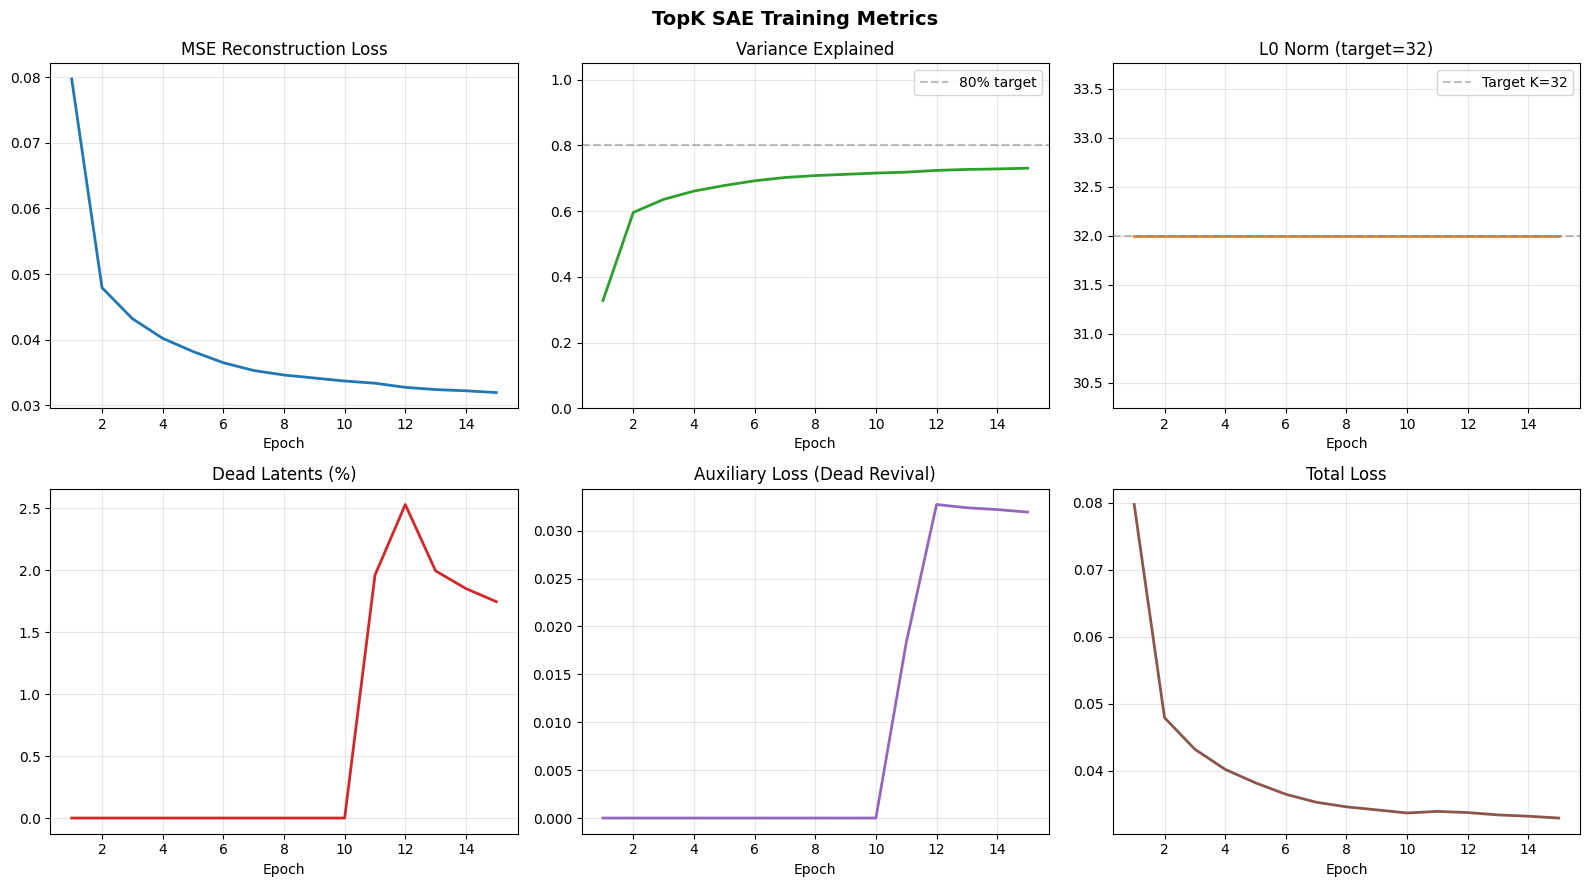

In [27]:
# Plot training curves
trainer.plot_training()

In [28]:
# Save checkpoint
ckpt_path = str(Path(cfg.output_dir) / 'topk_sae_checkpoint.pt')
trainer.save_checkpoint(ckpt_path)

Checkpoint saved to sae_outputs/topk_sae_checkpoint.pt


---
## Phase 4: Interpretation & Visualization

This is where the results live. We:
1. **Find max-activating image patches** for each SAE latent
2. **Generate spatial heatmaps** showing where each feature fires
3. **Build feature grids** for visual inspection of monosemanticity
4. **Compute feature statistics** (sparsity, activation distributions)

In [29]:
class FeatureVisualizer:
    """
    Interprets trained SAE features by finding max-activating examples,
    generating spatial heatmaps, and producing visual feature grids.
    """
    
    def __init__(
        self,
        sae: TopKSAE,
        foundation_model: nn.Module,
        hook_layer: str,
        device: torch.device,
    ):
        self.sae = sae
        self.model = foundation_model
        self.hook_layer = hook_layer
        self.device = device
        
        self.sae.eval()
        self.model.eval()
    
    @torch.no_grad()
    def get_spatial_activations(
        self, images: torch.Tensor
    ) -> Tuple[torch.Tensor, Tuple[int, int]]:
        """
        Get SAE activations with spatial structure preserved.
        
        Returns:
            sae_acts: (B, H, W, d_sae) spatial SAE activations
            spatial_shape: (H, W) tuple
        """
        spatial_acts = []
        spatial_shape = None
        
        def hook_fn(module, input, output):
            nonlocal spatial_shape
            if isinstance(output, tuple):
                output = output[0]
            act = output.detach()
            if act.ndim == 4:
                spatial_shape = (act.shape[1], act.shape[2])
            elif act.ndim == 3:
                # Estimate spatial dims (assume square)
                n = act.shape[1]
                h = int(np.sqrt(n))
                spatial_shape = (h, n // h)
            spatial_acts.append(act)
        
        # Find and hook the layer
        module = self.model
        for part in self.hook_layer.split('.'):
            module = module[int(part)] if part.isdigit() else getattr(module, part)
        handle = module.register_forward_hook(hook_fn)
        
        # Forward pass
        images = images.to(self.device)
        _ = self.model(images)
        handle.remove()
        
        act = spatial_acts[0]
        B = act.shape[0]
        H, W = spatial_shape
        
        # Reshape to (B, H, W, C) if needed
        if act.ndim == 3:
            C = act.shape[-1]
            act = act.reshape(B, H, W, C)
        
        # Normalize (same as during training)
        d_model = act.shape[-1]
        flat = act.reshape(-1, d_model)
        avg_sq_norm = (flat ** 2).sum(dim=-1).mean()
        scale = (d_model / avg_sq_norm).sqrt()
        act = act * scale
        
        # Run through SAE encoder
        flat_normed = act.reshape(-1, d_model)
        c, _ = self.sae.encode(flat_normed)
        sae_acts = c.reshape(B, H, W, -1)
        
        return sae_acts, spatial_shape
    
    @torch.no_grad()
    def find_max_activating(
        self, 
        dataloader: DataLoader,
        top_k: int = 10,
        n_features: Optional[int] = None,
    ) -> Dict:
        """
        Find the top-k maximally activating images for each SAE feature.
        
        Returns dict with:
            'images': per-feature list of top-k (image_tensor, activation_value, spatial_heatmap)
            'feature_stats': per-feature activation statistics
        """
        d_sae = self.sae.d_sae
        if n_features is None:
            n_features = d_sae
        
        # Track top-k per feature: store (max_activation, image_idx, heatmap)
        # We'll store the max spatial activation per image per feature
        all_images = []
        feature_max_acts = [[] for _ in range(n_features)]  # (act_value, img_idx, heatmap)
        
        img_idx = 0
        print("Scanning dataset for max-activating examples...")
        for batch in tqdm(dataloader, desc="Scanning"):
            if isinstance(batch, (list, tuple)):
                images = batch[0]
            else:
                images = batch
            
            B = images.shape[0]
            sae_acts, spatial_shape = self.get_spatial_activations(images)
            # sae_acts: (B, H, W, d_sae)
            
            for b in range(B):
                all_images.append(images[b].cpu())
                
                # For each feature, get the max spatial activation for this image
                for f in range(min(n_features, d_sae)):
                    heatmap = sae_acts[b, :, :, f].cpu()  # (H, W)
                    max_act = heatmap.max().item()
                    
                    if max_act > 0:
                        feature_max_acts[f].append((
                            max_act,
                            img_idx,
                            heatmap.numpy(),
                        ))
                img_idx += 1
        
        # Sort and keep top-k per feature
        results = {}
        for f in range(n_features):
            sorted_acts = sorted(feature_max_acts[f], key=lambda x: x[0], reverse=True)
            results[f] = {
                'top_examples': sorted_acts[:top_k],
                'total_activations': len(sorted_acts),
                'max_activation': sorted_acts[0][0] if sorted_acts else 0.0,
            }
        
        return results, all_images
    
    @staticmethod
    def plot_feature_grid(
        feature_idx: int,
        examples: List,
        all_images: List[torch.Tensor],
        save_path: Optional[str] = None,
        denorm_mean: Tuple = (0.485, 0.456, 0.406),
        denorm_std: Tuple = (0.229, 0.224, 0.225),
    ):
        """
        Plot a feature's top-activating images with spatial heatmap overlays.
        
        Each column shows: original image | heatmap overlay
        """
        n_examples = len(examples)
        if n_examples == 0:
            print(f"Feature {feature_idx}: No activating examples found (dead feature).")
            return
        
        n_show = min(n_examples, 5)  # Show up to 5 examples
        fig, axes = plt.subplots(n_show, 2, figsize=(6, 3 * n_show))
        if n_show == 1:
            axes = axes.reshape(1, -1)
        
        fig.suptitle(
            f'Feature #{feature_idx} — Top {n_show} Max-Activating Images',
            fontsize=13, fontweight='bold'
        )
        
        for i in range(n_show):
            act_val, img_idx, heatmap = examples[i]
            img = all_images[img_idx].clone()
            
            # Denormalize image for display
            for c in range(3):
                img[c] = img[c] * denorm_std[c] + denorm_mean[c]
            img = img.clamp(0, 1)
            img_np = img.permute(1, 2, 0).numpy()
            
            # Original image
            axes[i, 0].imshow(img_np)
            axes[i, 0].set_title(f'Image #{img_idx} (act={act_val:.2f})', fontsize=9)
            axes[i, 0].axis('off')
            
            # Heatmap overlay
            axes[i, 1].imshow(img_np)
            # Upsample heatmap to image size
            from scipy.ndimage import zoom
            h_scale = img_np.shape[0] / heatmap.shape[0]
            w_scale = img_np.shape[1] / heatmap.shape[1]
            heatmap_up = zoom(heatmap, (h_scale, w_scale), order=1)
            axes[i, 1].imshow(heatmap_up, cmap='hot', alpha=0.6)
            axes[i, 1].set_title('Spatial Activation Heatmap', fontsize=9)
            axes[i, 1].axis('off')
        
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def plot_feature_dashboard(
        feature_results: Dict,
        d_sae: int,
        save_path: Optional[str] = None,
    ):
        """
        Overview dashboard: activation frequency and max activation per feature.
        """
        feature_ids = sorted(feature_results.keys())
        total_acts = [feature_results[f]['total_activations'] for f in feature_ids]
        max_acts = [feature_results[f]['max_activation'] for f in feature_ids]
        
        # Sort by total activations
        sorted_idx = np.argsort(total_acts)[::-1]
        
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        fig.suptitle('SAE Feature Dashboard', fontsize=14, fontweight='bold')
        
        # Activation frequency distribution
        axes[0].hist(total_acts, bins=50, color='steelblue', edgecolor='white')
        axes[0].set_xlabel('Number of Activating Images')
        axes[0].set_ylabel('Number of Features')
        axes[0].set_title('Feature Activation Frequency')
        axes[0].axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='Dead features')
        axes[0].legend()
        
        # Max activation distribution
        nonzero_max = [m for m in max_acts if m > 0]
        axes[1].hist(nonzero_max, bins=50, color='coral', edgecolor='white')
        axes[1].set_xlabel('Max Activation Value')
        axes[1].set_ylabel('Number of Features')
        axes[1].set_title('Max Activation Distribution (alive features)')
        
        # Log-scale sparsity
        log_acts = [np.log10(t + 1) for t in total_acts]
        axes[2].hist(log_acts, bins=50, color='mediumseagreen', edgecolor='white')
        axes[2].set_xlabel('log10(Activation Count + 1)')
        axes[2].set_ylabel('Number of Features')
        axes[2].set_title('Feature Sparsity (log scale)')
        
        n_dead = sum(1 for t in total_acts if t == 0)
        n_alive = len(total_acts) - n_dead
        fig.text(
            0.5, -0.02,
            f'Total features: {len(total_acts)} | Alive: {n_alive} ({n_alive/len(total_acts):.1%}) | Dead: {n_dead} ({n_dead/len(total_acts):.1%})',
            ha='center', fontsize=11
        )
        
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
        plt.show()

In [30]:
# ============================================================
# RUN INTERPRETATION
# ============================================================

# Create a smaller dataloader for interpretation
# (Use the same dataset or a dedicated test split)
interp_loader = DataLoader(
    dataset,  # Same dataset as harvesting, or a test split
    batch_size=16,
    shuffle=False,
    num_workers=4,
)

visualizer = FeatureVisualizer(
    sae=sae,
    foundation_model=model,
    hook_layer=cfg.hook_layer,
    device=device,
)

# Find max-activating examples
# NOTE: For a large dictionary, scanning all features is slow.
# Start with a subset (e.g., 200 features) for the PoC.
N_FEATURES_TO_ANALYZE = min(200, cfg.d_sae)
print(f"Analyzing top-activating examples for {N_FEATURES_TO_ANALYZE} features...")

feature_results, all_images = visualizer.find_max_activating(
    interp_loader,
    top_k=cfg.top_k_examples,
    n_features=N_FEATURES_TO_ANALYZE,
)

Analyzing top-activating examples for 200 features...
Scanning dataset for max-activating examples...


Scanning:   0%|          | 0/313 [00:00<?, ?it/s]

Traceback (most recent call last):
  File "/opt/conda/envs/mmm/lib/python3.11/multiprocessing/queues.py", line 244, in _feed
    obj = _ForkingPickler.dumps(obj)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/envs/mmm/lib/python3.11/multiprocessing/reduction.py", line 51, in dumps
    cls(buf, protocol).dump(obj)
  File "/opt/conda/envs/mmm/lib/python3.11/site-packages/torch/multiprocessing/reductions.py", line 428, in reduce_storage
    fd, size = storage._share_fd_cpu_()
               ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/envs/mmm/lib/python3.11/site-packages/torch/storage.py", line 297, in wrapper
    return fn(self, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/envs/mmm/lib/python3.11/site-packages/torch/storage.py", line 330, in _share_fd_cpu_
    return super()._share_fd_cpu_(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: unable to write to file </torch_2905_1846020347_3>: No space left on device (28)
E

RuntimeError: DataLoader worker (pid 2908) is killed by signal: Bus error. It is possible that dataloader's workers are out of shared memory. Please try to raise your shared memory limit.

In [ ]:
# Dashboard overview
visualizer.plot_feature_dashboard(
    feature_results,
    d_sae=cfg.d_sae,
    save_path=str(Path(cfg.output_dir) / 'feature_dashboard.png'),
)

In [ ]:
# ============================================================
# VISUALIZE INDIVIDUAL FEATURES
# ============================================================
# Find the most active features (most images activating them)

sorted_features = sorted(
    feature_results.items(),
    key=lambda x: x[1]['total_activations'],
    reverse=True
)

print("Top 20 most frequently activating features:")
print(f"{'Feature':>10} | {'Activations':>12} | {'Max Act':>8}")
print("-" * 38)
for feat_id, info in sorted_features[:20]:
    print(f"  #{feat_id:<7d} | {info['total_activations']:>12d} | {info['max_activation']:>8.2f}")

In [ ]:
# Plot grids for the top 5 most active features
output_vis_dir = Path(cfg.output_dir) / 'feature_visualizations'
output_vis_dir.mkdir(parents=True, exist_ok=True)

for feat_id, info in sorted_features[:5]:
    examples = info['top_examples']
    if len(examples) > 0:
        print(f"\n{'='*60}")
        print(f"Feature #{feat_id} — {info['total_activations']} activating images")
        print(f"{'='*60}")
        visualizer.plot_feature_grid(
            feature_idx=feat_id,
            examples=examples,
            all_images=all_images,
            save_path=str(output_vis_dir / f'feature_{feat_id:04d}.png'),
        )

In [ ]:
# ============================================================
# INTERACTIVE: Explore any feature by ID
# ============================================================

FEATURE_TO_EXPLORE = 0  # <-- Change this to explore different features

if FEATURE_TO_EXPLORE in feature_results:
    info = feature_results[FEATURE_TO_EXPLORE]
    print(f"Feature #{FEATURE_TO_EXPLORE}: {info['total_activations']} activating images, max={info['max_activation']:.2f}")
    visualizer.plot_feature_grid(
        feature_idx=FEATURE_TO_EXPLORE,
        examples=info['top_examples'],
        all_images=all_images,
    )
else:
    print(f"Feature #{FEATURE_TO_EXPLORE} not in analyzed set (analyzed {N_FEATURES_TO_ANALYZE} features).")

---
## Phase 5 (Optional): Downstream Probe

Train a simple linear classifier on SAE feature activations to predict cancer vs. normal.
This proves the SAE features are *clinically meaningful*, not just visually interesting.

In [ ]:
class LinearProbe(nn.Module):
    """Simple linear probe on SAE feature activations."""
    def __init__(self, d_sae: int, n_classes: int):
        super().__init__()
        self.linear = nn.Linear(d_sae, n_classes)
    
    def forward(self, x):
        return self.linear(x)


@torch.no_grad()
def extract_sae_features(
    sae: TopKSAE,
    foundation_model: nn.Module,
    hook_layer: str,
    dataloader: DataLoader,
    device: torch.device,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Extract SAE features for each image (mean-pooled over spatial dims).
    Returns (features, labels) tensors.
    """
    sae.eval()
    foundation_model.eval()
    
    all_features = []
    all_labels = []
    
    captured_acts = []
    
    def hook_fn(module, input, output):
        if isinstance(output, tuple):
            output = output[0]
        captured_acts.append(output.detach())
    
    # Register hook
    module = foundation_model
    for part in hook_layer.split('.'):
        module = module[int(part)] if part.isdigit() else getattr(module, part)
    handle = module.register_forward_hook(hook_fn)
    
    for batch in tqdm(dataloader, desc="Extracting SAE features"):
        images, labels = batch[0].to(device), batch[1]
        captured_acts.clear()
        
        _ = foundation_model(images)
        act = captured_acts[0]
        
        # Flatten spatial dims
        if act.ndim == 4:
            B, H, W, C = act.shape
            act_flat = act.reshape(B, H * W, C)
        elif act.ndim == 3:
            act_flat = act
        else:
            act_flat = act.unsqueeze(1)
        
        # Normalize
        d_model = act_flat.shape[-1]
        avg_sq_norm = (act_flat ** 2).sum(dim=-1).mean()
        scale = (d_model / avg_sq_norm).sqrt()
        act_flat = act_flat * scale
        
        # SAE encode each spatial position, then mean-pool
        B, N, C = act_flat.shape
        c, _ = sae.encode(act_flat.reshape(B * N, C))
        c = c.reshape(B, N, -1)
        
        # Mean pool over spatial positions → one feature vector per image
        pooled = c.mean(dim=1)  # (B, d_sae)
        
        all_features.append(pooled.cpu())
        all_labels.append(labels)
    
    handle.remove()
    return torch.cat(all_features, dim=0), torch.cat(all_labels, dim=0)


# Uncomment below once you have a labeled dataset:
# features, labels = extract_sae_features(sae, model, cfg.hook_layer, interp_loader, device)
# 
# # Train/test split
# n_train = int(0.8 * len(features))
# train_feats, test_feats = features[:n_train], features[n_train:]
# train_labels, test_labels = labels[:n_train], labels[n_train:]
# 
# # Train probe
# n_classes = len(labels.unique())
# probe = LinearProbe(cfg.d_sae, n_classes).to(device)
# probe_optimizer = torch.optim.Adam(probe.parameters(), lr=1e-3)
# 
# for epoch in range(50):
#     probe.train()
#     logits = probe(train_feats.to(device))
#     loss = F.cross_entropy(logits, train_labels.to(device))
#     probe_optimizer.zero_grad()
#     loss.backward()
#     probe_optimizer.step()
# 
# # Evaluate
# probe.eval()
# with torch.no_grad():
#     test_logits = probe(test_feats.to(device))
#     preds = test_logits.argmax(dim=-1).cpu()
#     accuracy = (preds == test_labels).float().mean().item()
#     print(f"Linear probe accuracy on SAE features: {accuracy:.1%}")

print("Linear probe code ready — uncomment once you have labeled data.")

---
## Summary & Next Steps

### What this notebook produces:
1. **Training curves** — MSE, variance explained, L0, dead latent count over training
2. **Feature dashboard** — activation frequency and sparsity distributions across all features
3. **Feature grids** — top-activating images with spatial heatmap overlays per feature
4. **Linear probe** (optional) — classification accuracy using SAE features

### Presentable results:
- "Our TopK SAE achieves X% variance explained with an average of K active latents."
- "Feature #N fires specifically on [glandular structures / stroma / necrosis / artifacts] with clear spatial localization."
- If probe works: "A linear classifier on SAE features achieves X% accuracy on cancer classification, demonstrating clinical relevance."

### Extending this:
- **Crosscoders:** Hook multiple Swin stages simultaneously, train a crosscoder with multi-layer input.
- **Transcoders:** Train a model mapping stage L activations to stage L+1 activations to understand feature transformation.
- **BatchTopK:** Replace `torch.topk` per sample with batch-level selection for variable sparsity.
- **Causal validation:** Ablate individual features and measure downstream task impact.

---
*Notebook for thesis: Mechanistic Interpretability of UMedPT*  
*TopK SAE approach following Anthropic's Scaling Monosemanticity methodology*